In [48]:
# Generic inputs for most ML tasks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
# This is new
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor

pd.options.display.float_format = '{:,.2f}'.format

# setup interactive notebook mode
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from IPython.display import display, HTML

In [49]:
# fetch data 

mco_syr_sw_data = pd.read_csv('flight_data\mco_syr_sw_22_23.csv')
mco_syr_jb_data = pd.read_csv('flight_data\mco_syr_jb_22_23.csv')
jfk_syr_jb_data = pd.read_csv('flight_data\jfk_syr_jb_22_23.csv')
jfk_syr_end_data = pd.read_csv('flight_data\jfk_syr_end_22_23.csv')
ord_syr_ua_data = pd.read_csv('flight_data\ord_syr_ua_22_23.csv')
ord_syr_aa_data = pd.read_csv('flight_data\ord_syr_aa_22_23.csv')
# mco_syr_sw_data.head()
# mco_syr_jb_data.head()
# jfk_syr_jb_data.head()
# jfk_syr_end_data.head()
# ord_syr_ua_data.head()
# ord_syr_aa_data.head()

In [50]:
dfs = [ord_syr_aa_data,ord_syr_ua_data,jfk_syr_end_data,jfk_syr_jb_data,mco_syr_jb_data,mco_syr_sw_data]
main_data = pd.concat(dfs,axis = 0)
main_data.head()
len(main_data)

,Unnamed: 0,Carrier_Code,Date,Flight_Number,Tail_Number,Destination_Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),...,Wheels-on Time,Taxi-In time (Minutes),arr_Delay_Carrier,arr_Delay_Weather,arr_Delay_National_Aviation_System,arr_Delay_Security,arr_Delay_Late_Aircraft_Arrival,arr_hour,arr_day,arr_year
0,0,MQ,2022-01-01,4316,N900AE,SYR,15:28,0:00,107,0,...,0:00,0,0,0,0,0,0,18,5,2022
1,1,MQ,2023-01-01,3392,N283NN,SYR,18:25,18:24,111,104,...,21:02,6,0,0,0,0,0,21,6,2023
2,2,MQ,2023-01-01,3518,N213NN,SYR,13:05,13:01,117,96,...,15:33,4,0,0,0,0,0,16,6,2023
3,3,MQ,2022-01-02,4134,N900AE,SYR,10:25,10:21,111,146,...,13:43,4,0,0,31,0,0,13,6,2022
4,4,MQ,2022-01-02,4253,N238NN,SYR,17:25,17:51,107,116,...,20:40,7,0,26,9,0,0,20,6,2022


5623

In [51]:
main_data.dtypes



Unnamed: 0                             int64
Carrier_Code                          object
Date                                  object
Flight_Number                          int64
Tail_Number                           object
Destination_Airport                   object
Scheduled departure time              object
Actual departure time                 object
Scheduled elapsed time (Minutes)       int64
Actual elapsed time (Minutes)          int64
Departure delay (Minutes)              int64
Wheels-off time                       object
Taxi-Out time (Minutes)                int64
dep_Delay_Carrier                      int64
dep_Delay_Weather                      int64
dep_Delay_National_Aviation_System     int64
dep_Delay_Security                     int64
dep_Delay_Late_Aircraft_Arrival        int64
dep_hour                               int64
dep_day                                int64
dep_year                               int64
dep_order                             object
Origin_Air

In [52]:
# main_data['dep_min'] = main_data['Scheduled departure time'].str.split(":").str[1].astype('int64')
# main_data['Date'] = pd.to_datetime( main_data['Date'],format ="%Y-%m-%d") 
# main_data['Scheduled departure time'] = pd.to_datetime( main_data['Scheduled departure time'],format ='%H:%M') 
# main_data['Actual Arrival Time'] = pd.to_datetime( main_data['Actual Arrival Time'],format ='%H:%M')
# #main_data['dep_day'] = main_data['Date'].dt.day_of_week.astype('int64') 
# #main_data['dep_year'] = main_data['Date'].dt.year.astype('int64')
# main_data.dtypes

In [53]:
sub_data = main_data.drop(columns = ['Unnamed: 0','Destination_Airport','Actual departure time','Scheduled elapsed time (Minutes)','Actual elapsed time (Minutes)',
                         'Departure delay (Minutes)','Wheels-off time','Taxi-Out time (Minutes)','dep_Delay_Carrier',
                         'dep_Delay_Weather','dep_Delay_National_Aviation_System','dep_Delay_Security','dep_Delay_Late_Aircraft_Arrival',
                         'dep_year','Actual Arrival Time','Wheels-on Time','Taxi-In time (Minutes)','arr_Delay_Carrier','arr_Delay_Weather',
                         'arr_Delay_National_Aviation_System','arr_Delay_Security','arr_Delay_Late_Aircraft_Arrival','arr_year'])

In [54]:
sub_data.dtypes


Carrier_Code                object
Date                        object
Flight_Number                int64
Tail_Number                 object
Scheduled departure time    object
dep_hour                     int64
dep_day                      int64
dep_order                   object
Origin_Airport              object
Scheduled Arrival Time      object
Arrival Delay (Minutes)      int64
arr_hour                     int64
arr_day                      int64
dtype: object

In [55]:
sub_data.head()

,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,dep_hour,dep_day,dep_order,Origin_Airport,Scheduled Arrival Time,Arrival Delay (Minutes),arr_hour,arr_day
0,MQ,2022-01-01,4316,N900AE,15:28,15,5,latter,ORD,18:15,0,18,5
1,MQ,2023-01-01,3392,N283NN,18:25,18,6,latter,ORD,21:16,-8,21,6
2,MQ,2023-01-01,3518,N213NN,13:05,13,6,latter,ORD,16:02,-25,16,6
3,MQ,2022-01-02,4134,N900AE,10:25,10,6,latter,ORD,13:16,31,13,6
4,MQ,2022-01-02,4253,N238NN,17:25,17,6,latter,ORD,20:12,35,20,6


In [56]:
sub_data['dep_min'] = sub_data['Scheduled departure time'].str.split(":").str[1].astype('int64')
def round_to_nearest_quarter(minute):
    if 0 <= minute < 14:
        return 0
    elif 15 <= minute < 29:
        return 15
    elif 30 <= minute < 44:
        return 30
    else:
        return 45

sub_data['dep_minutes'] = sub_data['dep_min'].apply(round_to_nearest_quarter).astype('object')
sub_data['dep_hours'] = sub_data['dep_hour'].astype('object')
sub_data['dep_min'] = sub_data['dep_min'].astype('object')
sub_data['arr_min'] = main_data['Scheduled Arrival Time'].str.split(":").str[1].astype('int64')
sub_data['arr_minutes'] = sub_data['arr_min'].apply(round_to_nearest_quarter).astype('object')
sub_data['arr_hours'] = sub_data['arr_hour'].astype('object')
sub_data['arr_min'] = sub_data['arr_min'].astype('object')
sub_data['Flight_Number'] = main_data['Flight_Number'].astype('object')
sub_data['dep_hour'] = main_data['dep_hour'].astype('object')
sub_data['dep_day'] = main_data['dep_day'].astype('object')
sub_data['arr_hour'] = main_data['arr_hour'].astype('object')
sub_data['arr_day'] = main_data['arr_day'].astype('object')
conditions = [
    (sub_data['Arrival Delay (Minutes)'] > 5),
    (sub_data['Arrival Delay (Minutes)'] >=-5) & (sub_data['Arrival Delay (Minutes)'] <= 5),
    (sub_data['Arrival Delay (Minutes)'] < -5)
]
choices = [2,1,0]
sub_data['arr_status'] = np.select(conditions, choices)
sub_data.dtypes
sub_data.head()

Carrier_Code                object
Date                        object
Flight_Number               object
Tail_Number                 object
Scheduled departure time    object
dep_hour                    object
dep_day                     object
dep_order                   object
Origin_Airport              object
Scheduled Arrival Time      object
Arrival Delay (Minutes)      int64
arr_hour                    object
arr_day                     object
dep_min                     object
dep_minutes                 object
dep_hours                   object
arr_min                     object
arr_minutes                 object
arr_hours                   object
arr_status                   int32
dtype: object

,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,dep_hour,dep_day,dep_order,Origin_Airport,Scheduled Arrival Time,Arrival Delay (Minutes),arr_hour,arr_day,dep_min,dep_minutes,dep_hours,arr_min,arr_minutes,arr_hours,arr_status
0,MQ,2022-01-01,4316,N900AE,15:28,15,5,latter,ORD,18:15,0,18,5,28,15,15,15,15,18,1
1,MQ,2023-01-01,3392,N283NN,18:25,18,6,latter,ORD,21:16,-8,21,6,25,15,18,16,15,21,0
2,MQ,2023-01-01,3518,N213NN,13:05,13,6,latter,ORD,16:02,-25,16,6,5,0,13,2,0,16,0
3,MQ,2022-01-02,4134,N900AE,10:25,10,6,latter,ORD,13:16,31,13,6,25,15,10,16,15,13,2
4,MQ,2022-01-02,4253,N238NN,17:25,17,6,latter,ORD,20:12,35,20,6,25,15,17,12,0,20,2


In [57]:
#sub_data.to_csv('sub_data.csv', index=False)

In [58]:
# Read and process weather data files for each airport
jfk_weather_data = pd.read_csv('weather_data/JFK_weather_data_sub_hourly_processed.csv')
syr_weather_data = pd.read_csv('weather_data/SYR_weather_data_sub_hourly_processed.csv')
ord_weather_data = pd.read_csv('weather_data/ORD_weather_data_sub_hourly_processed.csv')
mco_weather_data = pd.read_csv('weather_data/MCO_weather_data_sub_hourly_processed.csv')

# Combine weather data for all airports
weather_dfs = [jfk_weather_data, ord_weather_data, mco_weather_data]
weather_data = pd.concat(weather_dfs, axis=0)

# Define merging logic based on airport code
sub_data = pd.merge(sub_data, syr_weather_data, how='left', on=['Date', 'arr_hours', 'arr_minutes'])

sub_data = pd.merge(sub_data, weather_data, how='left', on=['Origin_Airport', 'Date', 'dep_hours', 'dep_minutes'])


sub_data.head()


,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,dep_hour,dep_day,dep_order,Origin_Airport,Scheduled Arrival Time,...,dep_pres,dep_rh,dep_snow_rate,dep_temp,dep_vis,dep_weather.description,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd
0,MQ,2022-01-01,4316,N900AE,15:28,15,5,latter,ORD,18:15,...,984,87,17.00,-0.80,1,Light snow,600,30,13.40,10.55
1,MQ,2023-01-01,3392,N283NN,18:25,18,6,latter,ORD,21:16,...,990,86,0.00,4.40,8,Overcast clouds,804,215,3.20,0.86
2,MQ,2023-01-01,3518,N213NN,13:05,13,6,latter,ORD,16:02,...,989,88,0.00,5.60,5,Overcast clouds,804,230,6.40,3.60
3,MQ,2022-01-02,4134,N900AE,10:25,10,6,latter,ORD,13:16,...,996,77,0.00,-6.10,11,Overcast clouds,804,340,8.90,4.09
4,MQ,2022-01-02,4253,N238NN,17:25,17,6,latter,ORD,20:12,...,999,69,0.00,-5.30,16,Scattered clouds,802,325,5.40,3.09


In [59]:
sub_data.isna().sum()

Carrier_Code                 0
Date                         0
Flight_Number                0
Tail_Number                 11
Scheduled departure time     0
dep_hour                     0
dep_day                      0
dep_order                    0
Origin_Airport               0
Scheduled Arrival Time       0
Arrival Delay (Minutes)      0
arr_hour                     0
arr_day                      0
dep_min                      0
dep_minutes                  0
dep_hours                    0
arr_min                      0
arr_minutes                  0
arr_hours                    0
arr_status                   0
arr_clouds                   0
arr_dewpt                    0
arr_precip_rate              0
arr_pres                     0
arr_rh                       0
arr_snow_rate                0
arr_temp                     0
arr_vis                      0
arr_weather.description      0
arr_weather.code             0
arr_wind_dir                 0
arr_wind_gust_spd            0
arr_wind

In [60]:
sub_data.columns

Index(['Carrier_Code', 'Date', 'Flight_Number', 'Tail_Number',
       'Scheduled departure time', 'dep_hour', 'dep_day', 'dep_order',
       'Origin_Airport', 'Scheduled Arrival Time', 'Arrival Delay (Minutes)',
       'arr_hour', 'arr_day', 'dep_min', 'dep_minutes', 'dep_hours', 'arr_min',
       'arr_minutes', 'arr_hours', 'arr_status', 'arr_clouds', 'arr_dewpt',
       'arr_precip_rate', 'arr_pres', 'arr_rh', 'arr_snow_rate', 'arr_temp',
       'arr_vis', 'arr_weather.description', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd', 'dep_clouds',
       'dep_dewpt', 'dep_precip_rate', 'dep_pres', 'dep_rh', 'dep_snow_rate',
       'dep_temp', 'dep_vis', 'dep_weather.description', 'dep_weather.code',
       'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd'],
      dtype='object')

In [61]:
#sub_data.to_csv('merged_data.csv', index=False)


In [62]:
sub_data.rename(columns={'Arrival Delay (Minutes)':'arr_delay'}, inplace=True)


In [63]:
sub_data.drop(columns= ['Carrier_Code','Date','Flight_Number','Tail_Number',
                       'Scheduled departure time','Scheduled Arrival Time','dep_order', 
                        'arr_hours','arr_minutes', 'dep_hours', 'dep_minutes',
                        'arr_weather.description', 'dep_weather.description','arr_delay'],inplace = True)


In [64]:

sub_data.dtypes

sub_data.head()

dep_hour              object
dep_day               object
Origin_Airport        object
arr_hour              object
arr_day               object
dep_min               object
arr_min               object
arr_status             int32
arr_clouds             int64
arr_dewpt            float64
arr_precip_rate      float64
arr_pres               int64
arr_rh                 int64
arr_snow_rate        float64
arr_temp             float64
arr_vis                int64
arr_weather.code       int64
arr_wind_dir           int64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dep_clouds             int64
dep_dewpt            float64
dep_precip_rate      float64
dep_pres               int64
dep_rh                 int64
dep_snow_rate        float64
dep_temp             float64
dep_vis                int64
dep_weather.code       int64
dep_wind_dir           int64
dep_wind_gust_spd    float64
dep_wind_spd         float64
dtype: object

,dep_hour,dep_day,Origin_Airport,arr_hour,arr_day,dep_min,arr_min,arr_status,arr_clouds,arr_dewpt,...,dep_precip_rate,dep_pres,dep_rh,dep_snow_rate,dep_temp,dep_vis,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd
0,15,5,ORD,18,5,28,15,1,100,6.00,...,1.00,984,87,17.00,-0.80,1,600,30,13.40,10.55
1,18,6,ORD,21,6,25,16,0,100,1.80,...,0.00,990,86,0.00,4.40,8,804,215,3.20,0.86
2,13,6,ORD,16,6,5,2,0,100,1.70,...,0.00,989,88,0.00,5.60,5,804,230,6.40,3.60
3,10,6,ORD,13,6,25,16,2,100,-6.20,...,0.00,996,77,0.00,-6.10,11,804,340,8.90,4.09
4,17,6,ORD,20,6,25,12,2,100,-5.60,...,0.00,999,69,0.00,-5.30,16,802,325,5.40,3.09


In [65]:
#sub_data.to_csv('merged_data.csv', index=False)


In [66]:
# define function to import viz libraries
import plotly
plotly.offline.init_notebook_mode(connected=True)
from plotly.graph_objs import *
from plotly import tools
import plotly.graph_objects as go
import seaborn as sns

In [67]:
#sub_data['Carrier_Code'].unique()

In [68]:
# sub_data["Carrier_Code"] = np.where(sub_data["Carrier_Code"] == "MQ", "AA", sub_data["Carrier_Code"])
# sub_data["Carrier_Code"] = np.where(sub_data["Carrier_Code"] == "9E", "DL", sub_data["Carrier_Code"])

In [69]:
sub_data['Origin_Airport'].unique()

array(['ORD', 'JFK', 'MCO'], dtype=object)

In [70]:
su_data = sub_data
# su_data.head()
# sub_data.columns
su_data['dep_hour'] = pd.Categorical(su_data['dep_hour'], categories=[i for i in range(24)])
su_data['dep_day'] = pd.Categorical(su_data['dep_day'], categories=[i for i in range(7)])
su_data['dep_min'] = pd.Categorical(su_data['dep_min'], categories=[i for i in range(60)])
su_data['arr_hour'] = pd.Categorical(su_data['arr_hour'], categories=[i for i in range(24)])
su_data['arr_day'] = pd.Categorical(su_data['arr_day'], categories=[i for i in range(7)])
su_data['arr_min'] = pd.Categorical(su_data['arr_min'], categories=[i for i in range(60)])
#su_data['Carrier_Code'] = pd.Categorical(su_data['Carrier_Code'], categories=['AA', 'UA', 'DL', 'B6', 'WN'])
su_data['Origin_Airport'] = pd.Categorical(su_data['Origin_Airport'], categories=['ORD', 'JFK', 'MCO'])
su_data['arr_weather.code'] = pd.Categorical(su_data['arr_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])
su_data['dep_weather.code'] = pd.Categorical(su_data['dep_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])

su_data.drop(columns=['arr_precip_rate', 'arr_snow_rate', 'dep_precip_rate', 'dep_snow_rate'],inplace = True)
su_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'arr_clouds', 'arr_dewpt',
       'arr_pres', 'arr_rh', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd', 'dep_clouds',
       'dep_dewpt', 'dep_pres', 'dep_rh', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd'],
      dtype='object')

In [71]:
# correl = subset_data.corr()
correl = su_data.corr(numeric_only=True)

trace = go.Heatmap(z=correl.values,
                  x=correl.index.values,
                  y=correl.columns.values)
data=[trace]
plotly.offline.iplot(data, filename='basic-heatmap')

In [72]:
su_data = pd.get_dummies(su_data, drop_first = True)
#su_data['arr_status'] = su_data['arr_status'].astype('object')
su_data.head()
su_data.dtypes
su_data.columns

,arr_status,arr_clouds,arr_dewpt,arr_pres,arr_rh,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
0,1,100,6.00,991,95,6.70,8,295,3.80,2.97,...,False,False,False,False,False,False,False,False,False,False
1,0,100,1.80,1000,88,3.60,12,300,2.20,0.90,...,False,False,False,False,False,False,False,False,True,False
2,0,100,1.70,999,79,5.00,13,250,3.20,3.10,...,False,False,False,False,False,False,False,False,True,False
3,2,100,-6.20,994,91,-5.00,6,300,9.60,5.70,...,False,False,False,False,False,False,False,False,True,False
4,2,100,-5.60,1003,91,-4.40,16,340,9.60,3.10,...,False,False,False,False,False,False,True,False,False,False


arr_status                int32
arr_clouds                int64
arr_dewpt               float64
arr_pres                  int64
arr_rh                    int64
                         ...   
dep_weather.code_801       bool
dep_weather.code_802       bool
dep_weather.code_803       bool
dep_weather.code_804       bool
dep_weather.code_900       bool
Length: 267, dtype: object

Index(['arr_status', 'arr_clouds', 'arr_dewpt', 'arr_pres', 'arr_rh',
       'arr_temp', 'arr_vis', 'arr_wind_dir', 'arr_wind_gust_spd',
       'arr_wind_spd',
       ...
       'dep_weather.code_721', 'dep_weather.code_731', 'dep_weather.code_741',
       'dep_weather.code_751', 'dep_weather.code_800', 'dep_weather.code_801',
       'dep_weather.code_802', 'dep_weather.code_803', 'dep_weather.code_804',
       'dep_weather.code_900'],
      dtype='object', length=267)

In [73]:
X_train, X_test, y_train, y_test = train_test_split(su_data.drop(columns = ['arr_status']), su_data['arr_status'],stratify = su_data['arr_status'], test_size=0.2, random_state=50)
# In the above split the stratify = y essentially makes sure the fractions of the classification is maintained
X_train
X_test
y_train.dtypes
y_test

,arr_clouds,arr_dewpt,arr_pres,arr_rh,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,dep_clouds,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
5487,25,4.10,998,39,18.30,16,270,9.30,5.09,100,...,False,False,False,False,False,False,False,False,True,False
2914,0,16.40,999,87,18.60,16,135,2.20,1.50,87,...,False,False,False,False,False,False,False,False,True,False
451,87,18.80,996,81,22.20,16,270,6.80,3.10,87,...,False,False,False,False,False,False,False,False,True,False
1322,50,11.50,1006,49,22.80,16,110,5.20,2.10,0,...,False,False,False,False,True,False,False,False,False,False
5504,87,11.80,1002,42,25.70,16,295,6.80,4.47,87,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5215,68,17.60,988,83,20.60,16,255,6.40,3.10,59,...,False,False,False,False,False,False,False,True,False,False
2568,25,5.10,1005,27,25.40,16,305,7.00,1.95,50,...,False,False,False,False,False,False,False,True,False,False
4128,100,7.90,993,63,14.80,16,310,4.20,2.72,96,...,False,False,False,False,False,False,False,False,True,False
4887,100,-9.40,993,81,-6.70,4,100,5.60,2.60,87,...,False,False,False,False,False,False,False,False,True,False


,arr_clouds,arr_dewpt,arr_pres,arr_rh,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,dep_clouds,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
4979,87,-3.70,1010,46,7.10,16,220,8.90,5.09,25,...,False,False,False,False,False,False,True,False,False,False
4823,50,1.60,1010,92,2.80,13,70,7.60,2.10,100,...,False,False,True,False,False,False,False,False,False,False
4796,100,-2.90,1014,69,2.20,16,260,4.80,4.09,37,...,False,False,False,False,False,False,True,False,False,False
1676,25,7.90,1006,39,22.50,16,240,4.10,2.22,100,...,False,False,False,False,False,False,False,False,True,False
5619,100,5.00,988,100,5.00,2,270,7.60,4.09,87,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481,87,10.60,1001,46,22.80,16,335,5.60,1.50,25,...,False,False,False,False,False,False,True,False,False,False
1150,37,-4.80,1001,49,5.00,16,260,4.20,2.10,87,...,False,False,False,False,False,False,False,False,True,False
1129,78,2.90,1003,66,8.90,16,60,3.80,1.95,59,...,False,False,False,False,False,False,False,True,False,False
474,87,14.80,999,78,18.80,16,345,4.40,3.47,75,...,False,False,False,False,False,False,False,False,True,False


dtype('int32')

4979    2
4823    2
4796    0
1676    0
5619    0
       ..
481     0
1150    0
1129    2
474     1
4217    1
Name: arr_status, Length: 1125, dtype: int32

In [74]:
# y = X_train['arr_status']
# u = X_test['arr_status']
# X_train.drop(columns=['arr_status'], inplace=True)
# X_test.drop(columns=['arr_status'], inplace=True)

In [75]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = pd.DataFrame(sc.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(sc.transform(X_test), columns = X_test.columns, index = X_test.index)
X_train
X_test
y_train
y_test

,arr_clouds,arr_dewpt,arr_pres,arr_rh,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,dep_clouds,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
5487,-1.75,-0.03,-0.33,-1.33,0.64,0.40,0.69,0.61,0.57,1.04,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00
2914,-2.60,1.29,-0.20,1.31,0.67,0.40,-0.82,-1.47,-1.04,0.63,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00
451,0.37,1.55,-0.59,0.98,1.03,0.40,0.69,-0.12,-0.32,0.63,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00
1322,-0.89,0.77,0.70,-0.78,1.09,0.40,-1.10,-0.59,-0.77,-2.12,...,-0.08,0.00,-0.14,0.00,4.58,-0.13,-0.49,-0.44,-1.00,0.00
5504,0.37,0.80,0.18,-1.17,1.38,0.40,0.97,-0.12,0.29,0.63,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5215,-0.28,1.42,-1.62,1.09,0.87,0.40,0.52,-0.24,-0.32,-0.26,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,2.27,-1.00,0.00
2568,-1.75,0.08,0.57,-1.99,1.35,0.40,1.08,-0.06,-0.83,-0.54,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,2.27,-1.00,0.00
4128,0.82,0.38,-0.98,-0.01,0.30,0.40,1.13,-0.88,-0.49,0.92,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00
4887,0.82,-1.48,-0.98,0.98,-1.84,-3.27,-1.21,-0.47,-0.54,0.63,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00


,arr_clouds,arr_dewpt,arr_pres,arr_rh,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,dep_clouds,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
4979,0.37,-0.87,1.21,-0.95,-0.47,0.40,0.13,0.49,0.57,-1.33,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,2.03,-0.44,-1.00,0.00
4823,-0.89,-0.30,1.21,1.58,-0.90,-0.51,-1.54,0.11,-0.77,1.04,...,-0.08,0.00,7.29,0.00,-0.22,-0.13,-0.49,-0.44,-1.00,0.00
4796,0.82,-0.78,1.73,0.32,-0.96,0.40,0.58,-0.71,0.12,-0.95,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,2.03,-0.44,-1.00,0.00
1676,-1.75,0.38,0.70,-1.33,1.06,0.40,0.35,-0.91,-0.71,1.04,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00
5619,0.82,0.07,-1.62,2.02,-0.68,-3.88,0.69,0.11,0.12,0.63,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481,0.37,0.67,0.05,-0.95,1.09,0.40,1.41,-0.47,-1.04,-1.33,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,2.03,-0.44,-1.00,0.00
1150,-1.34,-0.98,0.05,-0.78,-0.68,0.40,0.58,-0.88,-0.77,0.63,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00
1129,0.07,-0.16,0.31,0.15,-0.29,0.40,-1.66,-1.00,-0.83,-0.26,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,2.27,-1.00,0.00
474,0.37,1.12,-0.20,0.81,0.69,0.40,1.52,-0.82,-0.15,0.25,...,-0.08,0.00,-0.14,0.00,-0.22,-0.13,-0.49,-0.44,1.00,0.00


5487    2
2914    2
451     2
1322    2
5504    2
       ..
5215    2
2568    2
4128    1
4887    0
1636    2
Name: arr_status, Length: 4498, dtype: int32

4979    2
4823    2
4796    0
1676    0
5619    0
       ..
481     0
1150    0
1129    2
474     1
4217    1
Name: arr_status, Length: 1125, dtype: int32

In [76]:
#model = LogisticRegression(fit_intercept = True, solver='newton-cg', multi_class = 'multinomial', penalty = 'none', max_iter = 1000)
model = LogisticRegression(fit_intercept = True, solver='lbfgs', multi_class = 'ovr', penalty = 'none', max_iter = 1000)
# model = LogisticRegression(fit_intercept = True, solver='lbfgs', multi_class = 'multinomial', penalty = None, max_iter = 1000)
#model = LinearRegression(fit_intercept = True)
# model = LogisticRegression(fit_intercept = True, solver='newton-cg', multi_class = 'multinomial', penalty = 'none', max_iter = 10000)

# While using multiclass case do multi_class = 'ovr' or 'auto'; can also try other solvers
# While doing regularization, use penalty = 'l2' and also C = 10.0 (need to try other values too)

model.fit(X_train, y_train) 

# The following gives the mean accuracy on the given data and labels
model.score(X_train, y_train) 

# This is the coefficient Beta_1, ..., Beta_7
model.coef_

# This is the coefficient Beta_0
model.intercept_

C:\Users\gurud\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1182: FutureWarning:

`penalty='none'`has been deprecated in 1.2 and will be removed in 1.4. To keep the past behaviour, set `penalty=None`.



LogisticRegression(max_iter=1000, multi_class='ovr', penalty='none')

0.582258781680747

array([[ 3.05654332e-01, -2.11420200e-01, -9.12056549e-02,
        -1.46328275e-01,  1.68729683e-01,  7.31969846e-02,
        -1.18616253e-01,  3.42393033e-03, -1.26962785e-01,
        -5.37041296e-02,  6.41933014e-01,  8.83579891e-02,
        -4.52023170e-01, -7.49850186e-01,  1.10331654e-01,
        -9.45387992e-02, -2.82798698e-01,  7.11786616e-02,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         9.04997031e-01,  8.93240458e+00,  9.15180569e+00,
         4.31569575e+00,  4.04874783e+00,  3.37405259e+00,
         4.24206665e+00,  1.67686995e+00,  4.59722345e-01,
        -6.39878329e-01, -8.57860787e-01, -3.87841608e+00,
        -2.68573675e+00, -3.36615216e+00, -7.85802218e+00,
        -1.14958578e+01, -1.62383918e+00,  5.60702642e-02,
         7.68429847e-02,  5.75027532e-02,  7.67449846e-05,
         1.83715712e-02,  2.91988964e-02,  3.57961823e+00,
        -1.83892751e-01,  0.00000000e+00,  5.91399736e-0

array([-0.41662797, -1.46053476, -0.93839592])

In [77]:
model.score(X_test,y_test)


0.5208888888888888

In [78]:
linear_reg_output = pd.DataFrame(model.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
linear_reg_output = linear_reg_output.merge(y_test, left_index = True, right_index = True)
linear_reg_output.head(20)
# mean_absolute_error = abs(linear_reg_output['pred_delay'] - linear_reg_output['arr_delay']).mean()
# print('Mean absolute error is ')
# print(mean_absolute_error)
# maer = mean_absolute_error/linear_reg_output['pred_delay'].mean()
# print('Mean absolute error ratio is ')
# print(maer)
model.score(X_test, y_test)

,pred_arr_status,arr_status
4979,0,2
4823,1,2
4796,0,0
1676,0,0
5619,2,0
2800,0,1
1844,2,2
2037,0,0
4406,1,2
3978,2,2


0.5208888888888888

In [79]:
from sklearn.tree import DecisionTreeClassifier
# from sklearn.tree import DecisionTreeRegressor
clf = DecisionTreeClassifier(random_state=50, min_samples_leaf = 3)

clf = clf.fit(X_train, y_train) 
clf.score(X_train, y_train)

clf.feature_importances_
linear_reg_output = pd.DataFrame(clf.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
linear_reg_output = linear_reg_output.merge(y_test, left_index = True, right_index = True)
linear_reg_output.head(20)
clf.score(X_test, y_test)

0.8610493552690085

array([0.02627789, 0.04845223, 0.04071534, 0.04362499, 0.04926384,
       0.00757911, 0.05242207, 0.05770697, 0.04190284, 0.02053619,
       0.06724636, 0.04854177, 0.06061505, 0.04047968, 0.00917173,
       0.06107874, 0.0584385 , 0.04912105, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.00056429, 0.00210122, 0.        , 0.00172328, 0.00223133,
       0.00138126, 0.00022368, 0.00397129, 0.00301582, 0.00132531,
       0.        , 0.00118667, 0.        , 0.00167585, 0.00565295,
       0.        , 0.00170605, 0.00343767, 0.00178421, 0.00587584,
       0.00168354, 0.00297489, 0.00285996, 0.01012703, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.00145395, 0.00627918,
       0.00086278, 0.00024581, 0.00363381, 0.        , 0.00293083,
       0.0024934 , 0.        , 0.00145737, 0.00047932, 0.00492289,
       0.0041902 , 0.00811064, 0.00196475, 0.00533842, 0.00642

,pred_arr_status,arr_status
4979,2,2
4823,0,2
4796,0,0
1676,0,0
5619,2,0
2800,1,1
1844,2,2
2037,2,0
4406,2,2
3978,1,2


0.4222222222222222

0.7129835482436638

<Axes: title={'center': 'Feature Importances'}>

Text(0, 0.5, 'Feature Importance Score')

<Figure size 2000x1000 with 0 Axes>

dep_dewpt           0.06
arr_rh              0.05
dep_temp            0.05
arr_dewpt           0.05
arr_temp            0.05
dep_wind_gust_spd   0.05
dep_rh              0.05
dep_wind_spd        0.04
arr_wind_dir        0.04
dep_pres            0.04
arr_wind_gust_spd   0.04
arr_wind_spd        0.04
dtype: float64

,pred_Y
4979,0
4823,0
4796,0
1676,0
5619,0


,pred_Y,arr_status
4979,0,2
4823,0,2
4796,0,0
1676,0,0
5619,0,0


Fraction of correct classification 


0.5253333333333333

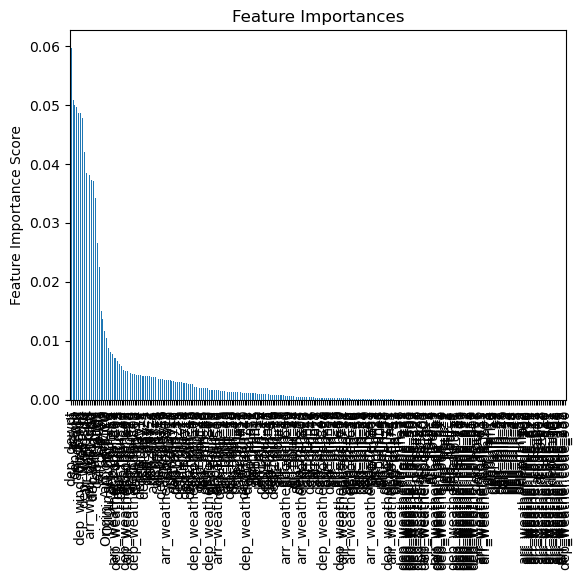

<Figure size 2000x1000 with 0 Axes>

In [80]:
rf = RandomForestClassifier(random_state=50, min_samples_leaf = 6, max_features = "sqrt", n_estimators = 100)

rf = rf.fit(X_train, y_train) 
rf.score(X_train, y_train) 

# rf.feature_importances_
feat_imp = pd.Series(rf.feature_importances_, X_train.columns.values).sort_values(ascending=False)

feat_imp_table = pd.DataFrame(feat_imp)
feat_imp_table = feat_imp_table.reset_index()
feat_imp_table.columns = ['Features', 'Values']
feat_imp.plot(kind='bar', title='Feature Importances')
plt.ylabel('Feature Importance Score')
plt.figure(figsize=[40,20], dpi = 50)
feat_imp.head(12)

test_output = pd.DataFrame(rf.predict(X_test), index = X_test.index, columns = ['pred_Y'])

test_output.head()
test_output = test_output.merge(y_test, left_index = True, right_index = True)
test_output.head()
print('Fraction of correct classification ')
rf.score(X_test, y_test) 

In [81]:
gb = GradientBoostingClassifier(random_state=50, min_samples_split = 12, min_samples_leaf = 6, max_depth = 4, n_estimators = 300)

gb = gb.fit(X_train, y_train) 
gb.score(X_train, y_train) 

0.8841707425522455

In [82]:
linear_reg_output = pd.DataFrame(gb.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
linear_reg_output = linear_reg_output.merge(y_test, left_index = True, right_index = True)
linear_reg_output.head(20)
gb.score(X_test,y_test)

,pred_arr_status,arr_status
4979,0,2
4823,0,2
4796,0,0
1676,0,0
5619,0,0
2800,1,1
1844,2,2
2037,2,0
4406,0,2
3978,0,2


0.5226666666666666

In [83]:
pred_data1 = pd.read_csv('pred_data1.csv')
pred_data1.head()
pred_data1.dtypes

,Unnamed: 0,dep_hour,dep_day,Origin_Airport,arr_hour,arr_day,dep_min,arr_min,arr_clouds,arr_dewpt,...,dep_clouds,dep_dewpt,dep_pres,dep_rh,dep_temp,dep_vis,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd
0,0,18,2,ORD,21,2,52,47,77,7.00,...,84,3.80,983.50,43,16.40,24.13,804,73,4.43,3.33
1,2,13,2,JFK,14,2,33,50,84,9.40,...,93,8.00,"1,015.00",77,11.90,0.10,804,96,4.33,3.60
2,4,11,2,MCO,13,2,5,45,86,9.50,...,58,17.70,"1,015.00",63,25.20,26.50,803,150,9.60,6.40
3,6,18,3,ORD,21,3,52,47,89,11.40,...,82,5.70,971.50,70,10.90,24.10,301,323,16.93,11.33
4,8,13,3,JFK,14,3,33,50,92,11.10,...,95,9.60,"1,011.00",81,12.70,24.13,804,140,9.46,6.26


Unnamed: 0             int64
dep_hour               int64
dep_day                int64
Origin_Airport        object
arr_hour               int64
arr_day                int64
dep_min                int64
arr_min                int64
arr_clouds             int64
arr_dewpt            float64
arr_pres             float64
arr_rh                 int64
arr_temp             float64
arr_vis              float64
arr_weather.code       int64
arr_wind_dir           int64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dep_clouds             int64
dep_dewpt            float64
dep_pres             float64
dep_rh                 int64
dep_temp             float64
dep_vis              float64
dep_weather.code       int64
dep_wind_dir           int64
dep_wind_gust_spd    float64
dep_wind_spd         float64
dtype: object

In [84]:

pred_data1['dep_min'] = pred_data1['dep_min'].astype('object')
pred_data1['arr_min'] = pred_data1['arr_min'].astype('object')
pred_data1['dep_hour'] = pred_data1['dep_hour'].astype('object')
pred_data1['dep_day'] = pred_data1['dep_day'].astype('object')
pred_data1['arr_hour'] = pred_data1['arr_hour'].astype('object')
pred_data1['arr_day'] = pred_data1['arr_day'].astype('object')
pred_data1['dep_weather.code'] = pred_data1['dep_weather.code'].astype('object')
pred_data1['arr_weather.code'] = pred_data1['arr_weather.code'].astype('object')
pred_data1.drop(columns=['Unnamed: 0'],inplace=True)

pred_data1.dtypes

dep_hour              object
dep_day               object
Origin_Airport        object
arr_hour              object
arr_day               object
dep_min               object
arr_min               object
arr_clouds             int64
arr_dewpt            float64
arr_pres             float64
arr_rh                 int64
arr_temp             float64
arr_vis              float64
arr_weather.code      object
arr_wind_dir           int64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dep_clouds             int64
dep_dewpt            float64
dep_pres             float64
dep_rh                 int64
dep_temp             float64
dep_vis              float64
dep_weather.code      object
dep_wind_dir           int64
dep_wind_gust_spd    float64
dep_wind_spd         float64
dtype: object

In [85]:
pred_data1['dep_hour'] = pd.Categorical(pred_data1['dep_hour'], categories=[i for i in range(24)])
pred_data1['dep_day'] = pd.Categorical(pred_data1['dep_day'], categories=[i for i in range(7)])
pred_data1['dep_min'] = pd.Categorical(pred_data1['dep_min'], categories=[i for i in range(60)])
pred_data1['arr_hour'] = pd.Categorical(pred_data1['arr_hour'], categories=[i for i in range(24)])
pred_data1['arr_day'] = pd.Categorical(pred_data1['arr_day'], categories=[i for i in range(7)])
pred_data1['arr_min'] = pd.Categorical(pred_data1['arr_min'], categories=[i for i in range(60)])
#su_data['Carrier_Code'] = pd.Categorical(su_data['Carrier_Code'], categories=['AA', 'UA', 'DL', 'B6', 'WN'])
pred_data1['Origin_Airport'] = pd.Categorical(pred_data1['Origin_Airport'], categories=['ORD', 'JFK', 'MCO'])
pred_data1['arr_weather.code'] = pd.Categorical(pred_data1['arr_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])
pred_data1['dep_weather.code'] = pd.Categorical(pred_data1['dep_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])



In [86]:
pred_data1 = pd.get_dummies(pred_data1, drop_first = True)
#su_data['arr_status'] = su_data['arr_status'].astype('object')
pred_data1.head()
pred_data1.dtypes
pred_data1.columns

,arr_clouds,arr_dewpt,arr_pres,arr_rh,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,dep_clouds,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
0,77,7.00,999.00,66,13.30,24.13,100,4.13,2.66,84,...,False,False,False,False,False,False,False,False,True,False
1,84,9.40,997.50,60,17.20,19.70,280,6.90,4.40,93,...,False,False,False,False,False,False,False,False,True,False
2,86,9.50,997.50,62,16.80,22.10,256,6.73,4.26,58,...,False,False,False,False,False,False,False,True,False,False
3,89,11.40,983.50,70,16.90,4.08,150,17.10,11.33,82,...,False,False,False,False,False,False,False,False,False,False
4,92,11.10,988.50,64,18.00,24.13,140,16.40,10.80,95,...,False,False,False,False,False,False,False,False,True,False


arr_clouds                int64
arr_dewpt               float64
arr_pres                float64
arr_rh                    int64
arr_temp                float64
                         ...   
dep_weather.code_801       bool
dep_weather.code_802       bool
dep_weather.code_803       bool
dep_weather.code_804       bool
dep_weather.code_900       bool
Length: 266, dtype: object

Index(['arr_clouds', 'arr_dewpt', 'arr_pres', 'arr_rh', 'arr_temp', 'arr_vis',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd', 'dep_clouds',
       ...
       'dep_weather.code_721', 'dep_weather.code_731', 'dep_weather.code_741',
       'dep_weather.code_751', 'dep_weather.code_800', 'dep_weather.code_801',
       'dep_weather.code_802', 'dep_weather.code_803', 'dep_weather.code_804',
       'dep_weather.code_900'],
      dtype='object', length=266)

In [87]:
from sklearn.preprocessing import StandardScaler
#sc = StandardScaler()
X_test = pd.DataFrame(sc.transform(pred_data1), columns = pred_data1.columns, index = pred_data1.index)


In [91]:
linear_reg_output = pd.DataFrame(gb.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
#linear_reg_output = linear_reg_output.merge(y_test, left_index = True, right_index = True)
linear_reg_output.head(30)
# mean_absolute_error = abs(linear_reg_output['pred_delay'] - linear_reg_output['arr_delay']).mean()
# print('Mean absolute error is ')
# print(mean_absolute_error)
# maer = mean_absolute_error/linear_reg_output['pred_delay'].mean()
# print('Mean absolute error ratio is ')
# print(maer)
#model.score(X_test, y_test)

,pred_arr_status
0,0
1,0
2,0
3,2
4,0
5,1
6,1
7,2
8,1
9,0


In [90]:
pred_data1.head(20)

,arr_clouds,arr_dewpt,arr_pres,arr_rh,arr_temp,arr_vis,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,dep_clouds,...,dep_weather.code_721,dep_weather.code_731,dep_weather.code_741,dep_weather.code_751,dep_weather.code_800,dep_weather.code_801,dep_weather.code_802,dep_weather.code_803,dep_weather.code_804,dep_weather.code_900
0,77,7.00,999.00,66,13.30,24.13,100,4.13,2.66,84,...,False,False,False,False,False,False,False,False,True,False
1,84,9.40,997.50,60,17.20,19.70,280,6.90,4.40,93,...,False,False,False,False,False,False,False,False,True,False
2,86,9.50,997.50,62,16.80,22.10,256,6.73,4.26,58,...,False,False,False,False,False,False,False,True,False,False
3,89,11.40,983.50,70,16.90,4.08,150,17.10,11.33,82,...,False,False,False,False,False,False,False,False,False,False
4,92,11.10,988.50,64,18.00,24.13,140,16.40,10.80,95,...,False,False,False,False,False,False,False,False,True,False
5,92,11.10,988.50,64,18.00,24.13,140,16.40,10.80,57,...,False,False,False,False,False,False,False,True,False,False
6,76,3.20,975.00,62,10.10,22.62,233,14.25,9.43,26,...,False,False,False,False,False,False,True,False,False,False
7,82,7.00,972.50,59,14.90,17.46,230,14.10,9.67,65,...,False,False,False,False,False,False,False,False,False,False
8,82,7.00,972.50,59,14.90,17.46,230,14.10,9.67,7,...,False,False,False,False,False,True,False,False,False,False
9,75,1.10,992.30,66,7.00,24.13,276,13.70,6.17,36,...,False,False,False,False,False,False,True,False,False,False
